# Thực nghiệm trên dữ liệu tự crawl


## Chuẩn bị dữ liệu


In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import LogisticRegression as SklearnLogisticRegression
from sklearn.metrics import accuracy_score, precision_recall_fscore_support


np.random.seed(42)

if hasattr(sys.stdout, "reconfigure"):
    sys.stdout.reconfigure(encoding="utf-8")

duong_dan = Path("du_lieu_crawl/dataset_crawl.npz")
du_lieu = np.load(duong_dan)

X_train = du_lieu["X_train"]
y_train = du_lieu["y_train"]
X_test = du_lieu["X_test"]
y_test = du_lieu["y_test"]


## Logistic Regression


In [2]:
def sigmoid(z):
    z = np.clip(z, -40, 40)
    return 1 / (1 + np.exp(-z))


class LogisticRegression:
    def __init__(self, learning_rate=0.2, so_epoch=100):
        self.learning_rate = learning_rate
        self.so_epoch = so_epoch
        self.loss = []

    def fit(self, X, y):
        self.w = np.zeros(X.shape[1])
        self.b = 0.0

        for _ in range(self.so_epoch):
            xac_suat = sigmoid(X @ self.w + self.b)
            sai_so = xac_suat - y
            self.w -= self.learning_rate * (X.T @ sai_so / len(X))
            self.b -= self.learning_rate * np.mean(sai_so)
            gia_tri_loss = -np.mean(
                y * np.log(xac_suat + 1e-8)
                + (1 - y) * np.log(1 - xac_suat + 1e-8)
            )
            self.loss.append(gia_tri_loss)

    def predict(self, X):
        return (sigmoid(X @ self.w + self.b) >= 0.5).astype(int)


## Softmax Regression


In [3]:
class SoftmaxRegression:
    def __init__(self, learning_rate=0.2, so_epoch=200):
        self.learning_rate = learning_rate
        self.so_epoch = so_epoch
        self.loss = []

    def softmax(self, z):
        z = z - np.max(z, axis=1, keepdims=True)
        exp_z = np.exp(z)
        return exp_z / np.sum(exp_z, axis=1, keepdims=True)

    def fit(self, X, y):
        so_lop = len(np.unique(y))
        self.W = np.zeros((X.shape[1], so_lop))
        self.b = np.zeros(so_lop)
        y_one_hot = np.eye(so_lop)[y]

        for _ in range(self.so_epoch):
            xac_suat = self.softmax(X @ self.W + self.b)
            sai_so = xac_suat - y_one_hot
            self.W -= self.learning_rate * (X.T @ sai_so / len(X))
            self.b -= self.learning_rate * np.mean(sai_so, axis=0)
            gia_tri_loss = -np.mean(
                np.sum(y_one_hot * np.log(xac_suat + 1e-8), axis=1)
            )
            self.loss.append(gia_tri_loss)

    def predict(self, X):
        return np.argmax(X @ self.W + self.b, axis=1)


def in_ket_qua(y_that, y_du_doan, trung_binh):
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_that, y_du_doan, average=trung_binh, zero_division=0
    )
    print(f"Accuracy : {accuracy_score(y_that, y_du_doan):.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall   : {recall:.4f}")
    print(f"F1-score : {f1:.4f}")


## Huấn luyện và đánh giá


LOGISTIC REGRESSION
Accuracy : 0.8333
Precision: 1.0000
Recall   : 0.6667
F1-score : 0.8000


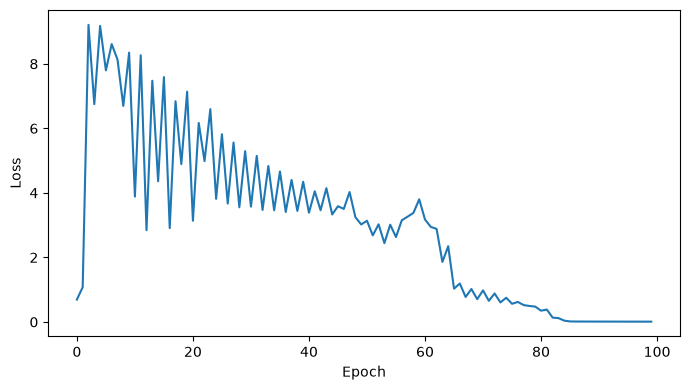


SOFTMAX REGRESSION
Accuracy : 0.3667
Precision: 0.4117
Recall   : 0.3667
F1-score : 0.3257


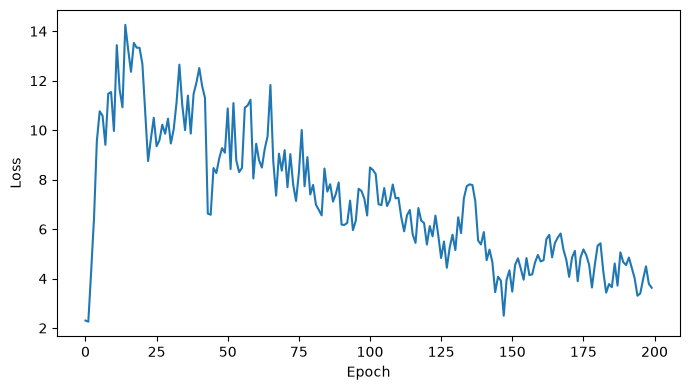


LOGISTIC REGRESSION SCIKIT-LEARN
Accuracy : 1.0000
Precision: 1.0000
Recall   : 1.0000
F1-score : 1.0000

SOFTMAX REGRESSION SCIKIT-LEARN


Accuracy : 0.4333
Precision: 0.4795
Recall   : 0.4333
F1-score : 0.4088


In [4]:
train_01 = np.isin(y_train, [0, 1])
test_01 = np.isin(y_test, [0, 1])
X_train_01 = X_train[train_01]
y_train_01 = y_train[train_01]
X_test_01 = X_test[test_01]
y_test_01 = y_test[test_01]

print("LOGISTIC REGRESSION")
logistic = LogisticRegression()
logistic.fit(X_train_01, y_train_01)
in_ket_qua(y_test_01, logistic.predict(X_test_01), "binary")

plt.figure(figsize=(7, 4))
plt.plot(logistic.loss)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.tight_layout()
plt.savefig("bonus_loss_logistic.png", dpi=150)
plt.show()

print("\nSOFTMAX REGRESSION")
softmax = SoftmaxRegression()
softmax.fit(X_train, y_train)
in_ket_qua(y_test, softmax.predict(X_test), "macro")

plt.figure(figsize=(7, 4))
plt.plot(softmax.loss)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.tight_layout()
plt.savefig("bonus_loss_softmax.png", dpi=150)
plt.show()

print("\nLOGISTIC REGRESSION SCIKIT-LEARN")
model_01 = SklearnLogisticRegression(max_iter=200, random_state=42)
model_01.fit(X_train_01, y_train_01)
in_ket_qua(y_test_01, model_01.predict(X_test_01), "binary")

print("\nSOFTMAX REGRESSION SCIKIT-LEARN")
model_10 = SklearnLogisticRegression(max_iter=200, random_state=42)
model_10.fit(X_train, y_train)
in_ket_qua(y_test, model_10.predict(X_test), "macro")
